In [1]:
from google.colab import files
import pandas as pd

uploaded = files.upload()
filename = next(iter(uploaded))
data = pd.read_csv(filename)

print("Dataset loaded:", data.shape)

Saving Data_for_UCI_named.csv to Data_for_UCI_named.csv
Dataset loaded: (10000, 14)


In [2]:
print("Dataset shape:", data.shape)

print("\nMissing values:")
print(data.isnull().sum())

print("\nDuplicate rows:", data.duplicated().sum())

print("\nTarget class counts:")
print(data["stabf"].value_counts())

Dataset shape: (10000, 14)

Missing values:
tau1     0
tau2     0
tau3     0
tau4     0
p1       0
p2       0
p3       0
p4       0
g1       0
g2       0
g3       0
g4       0
stab     0
stabf    0
dtype: int64

Duplicate rows: 0

Target class counts:
stabf
unstable    6380
stable      3620
Name: count, dtype: int64


In [3]:
# Select the 6 features used in your current experiment
X = data[['tau1', 'tau2', 'p1', 'p2', 'g1', 'g2']]

# Select the target
y = data['stabf']

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (10000, 6)
Target shape: (10000,)

Target distribution:
stabf
unstable    6380
stable      3620
Name: count, dtype: int64


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (8000, 6)
Testing features: (2000, 6)
Training target: (8000,)
Testing target: (2000,)


In [5]:
# Convert target labels to numbers
y_train = y_train.map({'stable': 0, 'unstable': 1})
y_test = y_test.map({'stable': 0, 'unstable': 1})

print(y_train.value_counts())
print(y_test.value_counts())

stabf
1    5104
0    2896
Name: count, dtype: int64
stabf
1    1276
0     724
Name: count, dtype: int64


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

# Train the models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(
        eval_metric="logloss",
        random_state=42
    )
}

# Train and evaluate
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    print(f"{name}: Accuracy = {accuracy_score(y_test, predictions):.4f}")

Logistic Regression: Accuracy = 0.7200
Decision Tree: Accuracy = 0.6720
Random Forest: Accuracy = 0.7490
Gradient Boosting: Accuracy = 0.7565
XGBoost: Accuracy = 0.7275


In [7]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, roc_auc_score
)
import pandas as pd

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    # Use probability scores for AUC when available
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "Error Rate": 1 - accuracy_score(y_test, y_pred),
        "MCC": matthews_corrcoef(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-score  Error Rate    MCC    AUC
Logistic Regression    0.7200     0.7483  0.8456    0.7940      0.2800 0.3688 0.7636
      Decision Tree    0.6720     0.7492  0.7304    0.7397      0.3280 0.2968 0.6497
      Random Forest    0.7490     0.7959  0.8158    0.8057      0.2510 0.4516 0.8073
  Gradient Boosting    0.7565     0.7924  0.8378    0.8145      0.2435 0.4626 0.8159
            XGBoost    0.7275     0.7758  0.8056    0.7905      0.2725 0.4019 0.7923


In [8]:
# Use all 12 input features, excluding both target columns
X12 = data.drop(columns=['stab', 'stabf'])

from sklearn.model_selection import train_test_split

X12_train, X12_test, y12_train, y12_test = train_test_split(
    X12, data['stabf'].map({'stable': 0, 'unstable': 1}),
    test_size=0.2,
    random_state=42,
    stratify=data['stabf']
)

print("12-feature training shape:", X12_train.shape)
print("12-feature testing shape:", X12_test.shape)

12-feature training shape: (8000, 12)
12-feature testing shape: (2000, 12)


In [9]:
models12 = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(
        eval_metric="logloss",
        random_state=42
    )
}

results12 = []

for name, model in models12.items():
    model.fit(X12_train, y12_train)
    pred = model.predict(X12_test)
    prob = model.predict_proba(X12_test)[:, 1]

    results12.append({
        "Model": name,
        "Accuracy": accuracy_score(y12_test, pred),
        "Precision": precision_score(y12_test, pred, zero_division=0),
        "Recall": recall_score(y12_test, pred, zero_division=0),
        "F1-score": f1_score(y12_test, pred, zero_division=0),
        "Error Rate": 1 - accuracy_score(y12_test, pred),
        "MCC": matthews_corrcoef(y12_test, pred),
        "AUC": roc_auc_score(y12_test, prob)
    })

results12_df = pd.DataFrame(results12)
print(results12_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-score  Error Rate    MCC    AUC
Logistic Regression    0.8205     0.8409  0.8864    0.8630      0.1795 0.6050 0.8922
      Decision Tree    0.8495     0.8818  0.8824    0.8821      0.1505 0.6741 0.8369
      Random Forest    0.9240     0.9226  0.9616    0.9417      0.0760 0.8342 0.9806
  Gradient Boosting    0.9360     0.9335  0.9687    0.9508      0.0640 0.8606 0.9841
            XGBoost    0.9465     0.9520  0.9647    0.9583      0.0535 0.8837 0.9910


In [10]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone
import pandas as pd

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "mcc": "matthews_corrcoef",
    "roc_auc": "roc_auc"
}

cv_results = []

for name, model in models12.items():
    scores = cross_validate(
        clone(model),
        X12_train,
        y12_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Precision Mean": scores["test_precision"].mean(),
        "Recall Mean": scores["test_recall"].mean(),
        "F1 Mean": scores["test_f1"].mean(),
        "MCC Mean": scores["test_mcc"].mean(),
        "AUC Mean": scores["test_roc_auc"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

print("5-Fold Stratified Cross-Validation Results")
print(cv_results_df.round(4).to_string(index=False))

5-Fold Stratified Cross-Validation Results
              Model  Accuracy Mean  Accuracy Std  Precision Mean  Recall Mean  F1 Mean  MCC Mean  AUC Mean
Logistic Regression         0.8140        0.0068          0.8381       0.8781   0.8576    0.5912    0.8895
      Decision Tree         0.8338        0.0073          0.8664       0.8742   0.8703    0.6390    0.8183
      Random Forest         0.9159        0.0121          0.9200       0.9508   0.9352    0.8165    0.9764
  Gradient Boosting         0.9161        0.0036          0.9110       0.9626   0.9361    0.8171    0.9761
            XGBoost         0.9409        0.0073          0.9444       0.9641   0.9541    0.8714    0.9883


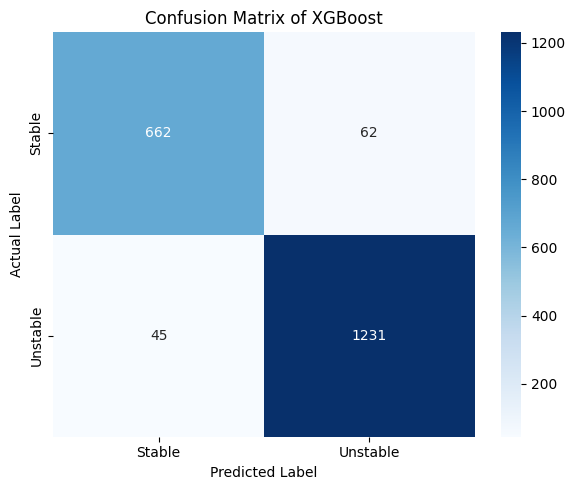

Confusion matrix:
[[ 662   62]
 [  45 1231]]


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Predict using the trained 12-feature XGBoost model
xgb_model = models12["XGBoost"]
y_pred_xgb = xgb_model.predict(X12_test)

cm = confusion_matrix(y12_test, y_pred_xgb, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stable", "Unstable"],
    yticklabels=["Stable", "Unstable"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix of XGBoost")
plt.tight_layout()
plt.savefig("fig4_xgboost_confusion_matrix.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrix:")
print(cm)

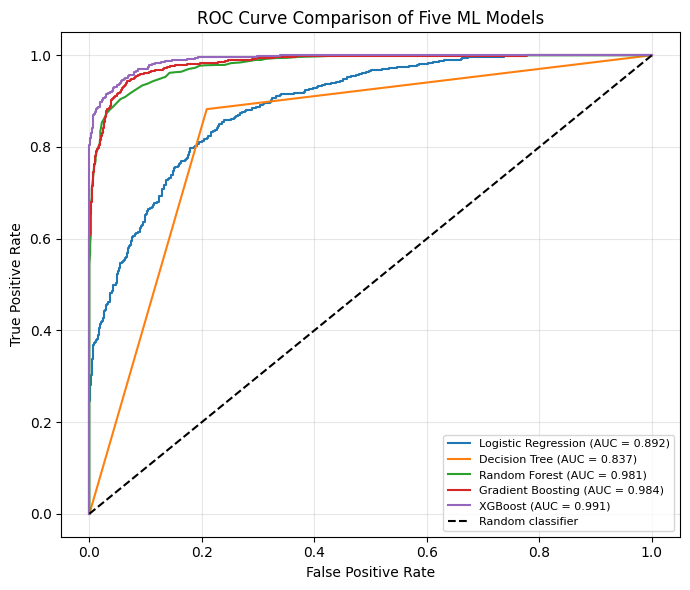

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(7, 6))

for name, model in models12.items():
    y_prob = model.predict_proba(X12_test)[:, 1]
    fpr, tpr, _ = roc_curve(y12_test, y_prob)
    auc_value = roc_auc_score(y12_test, y_prob)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of Five ML Models")
plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("fig5_roc_curve_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()

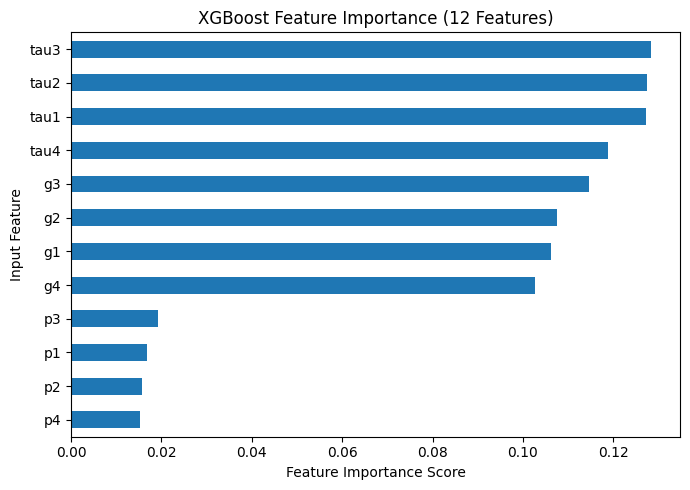

tau3    0.1283
tau2    0.1274
tau1    0.1272
tau4    0.1189
g3      0.1145
g2      0.1076
g1      0.1062
g4      0.1027
p3      0.0193
p1      0.0169
p2      0.0157
p4      0.0152
dtype: float32


In [13]:
import matplotlib.pyplot as plt
import pandas as pd

xgb_model = models12["XGBoost"]

importance = pd.Series(
    xgb_model.feature_importances_,
    index=X12_train.columns
).sort_values(ascending=True)

plt.figure(figsize=(7, 5))
importance.plot(kind="barh")

plt.xlabel("Feature Importance Score")
plt.ylabel("Input Feature")
plt.title("XGBoost Feature Importance (12 Features)")
plt.tight_layout()

plt.savefig(
    "fig3_feature_importance_12_features.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print(importance.sort_values(ascending=False).round(4))

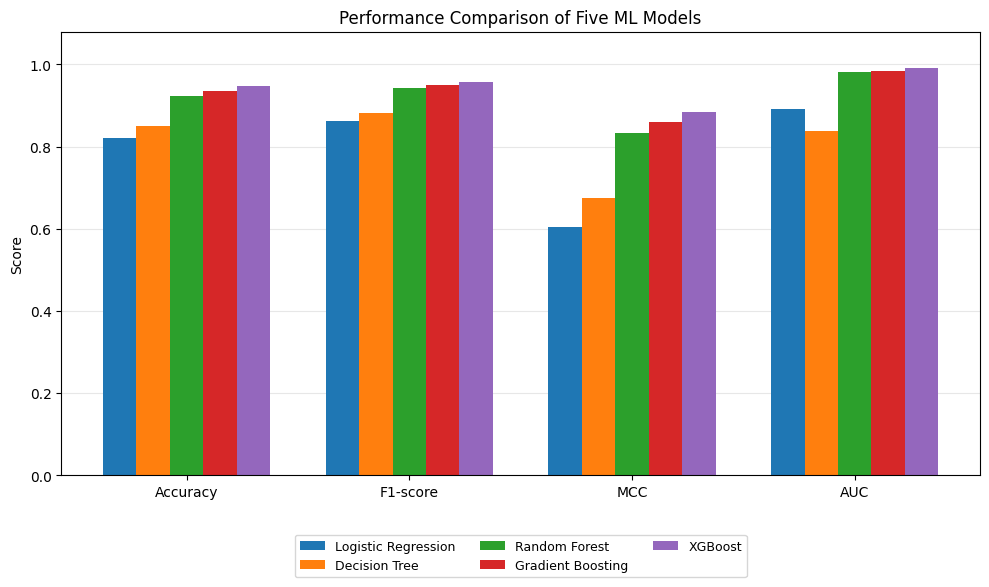

In [14]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "F1-score", "MCC", "AUC"]

values = {
    "Logistic Regression": [0.8205, 0.8630, 0.6050, 0.8922],
    "Decision Tree":       [0.8495, 0.8821, 0.6741, 0.8369],
    "Random Forest":       [0.9240, 0.9417, 0.8342, 0.9806],
    "Gradient Boosting":   [0.9360, 0.9508, 0.8606, 0.9841],
    "XGBoost":             [0.9465, 0.9583, 0.8837, 0.9910]
}

x = np.arange(len(metrics))
width = 0.15

fig, ax = plt.subplots(figsize=(10, 6))

for i, (model, scores) in enumerate(values.items()):
    positions = x + (i - 2) * width
    ax.bar(positions, scores, width, label=model)

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Score")
ax.set_title("Performance Comparison of Five ML Models")

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    fontsize=9,
    frameon=True
)

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig(
    "model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [15]:
# Combine the existing test-set results
results6_df = pd.DataFrame(results)
results12_df = pd.DataFrame(results12)

results6_df["Feature Set"] = "6 Features"
results12_df["Feature Set"] = "12 Features"

combined_results = pd.concat(
    [results6_df, results12_df],
    ignore_index=True
)

combined_results.to_csv(
    "six_vs_twelve_feature_results.csv",
    index=False
)

print(combined_results.round(4).to_string(index=False))
print("\nSaved: six_vs_twelve_feature_results.csv")

              Model  Accuracy  Precision  Recall  F1-score  Error Rate    MCC    AUC Feature Set
Logistic Regression    0.7200     0.7483  0.8456    0.7940      0.2800 0.3688 0.7636  6 Features
      Decision Tree    0.6720     0.7492  0.7304    0.7397      0.3280 0.2968 0.6497  6 Features
      Random Forest    0.7490     0.7959  0.8158    0.8057      0.2510 0.4516 0.8073  6 Features
  Gradient Boosting    0.7565     0.7924  0.8378    0.8145      0.2435 0.4626 0.8159  6 Features
            XGBoost    0.7275     0.7758  0.8056    0.7905      0.2725 0.4019 0.7923  6 Features
Logistic Regression    0.8205     0.8409  0.8864    0.8630      0.1795 0.6050 0.8922 12 Features
      Decision Tree    0.8495     0.8818  0.8824    0.8821      0.1505 0.6741 0.8369 12 Features
      Random Forest    0.9240     0.9226  0.9616    0.9417      0.0760 0.8342 0.9806 12 Features
  Gradient Boosting    0.9360     0.9335  0.9687    0.9508      0.0640 0.8606 0.9841 12 Features
            XGBoost    0.9465 

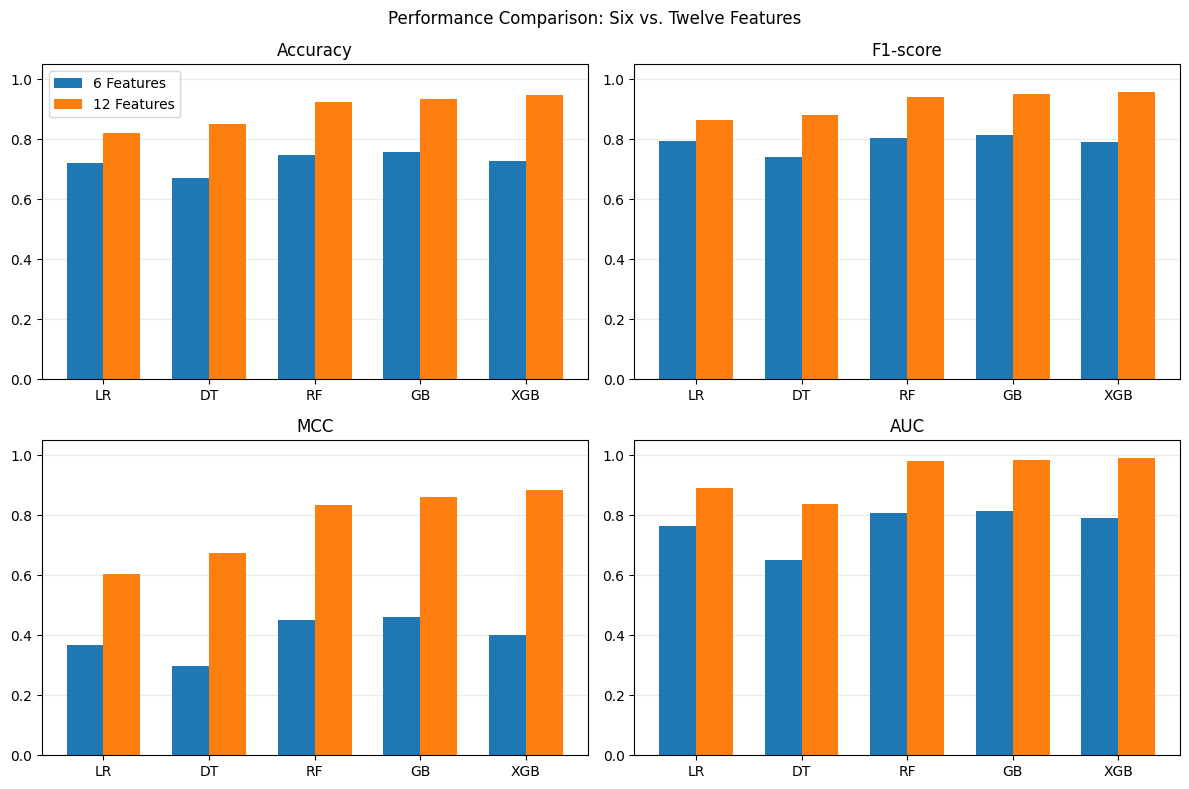

In [16]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "F1-score", "MCC", "AUC"]

comparison = combined_results.pivot(
    index="Model",
    columns="Feature Set",
    values=metrics
)

models_order = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "Gradient Boosting",
    "XGBoost"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

x = np.arange(len(models_order))
width = 0.35

for i, metric in enumerate(metrics):
    six_scores = [
        combined_results[
            (combined_results["Model"] == model) &
            (combined_results["Feature Set"] == "6 Features")
        ][metric].iloc[0]
        for model in models_order
    ]

    twelve_scores = [
        combined_results[
            (combined_results["Model"] == model) &
            (combined_results["Feature Set"] == "12 Features")
        ][metric].iloc[0]
        for model in models_order
    ]

    axes[i].bar(x - width/2, six_scores, width, label="6 Features")
    axes[i].bar(x + width/2, twelve_scores, width, label="12 Features")
    axes[i].set_title(metric)
    axes[i].set_xticks(x)
    axes[i].set_xticklabels(
        ["LR", "DT", "RF", "GB", "XGB"],
        rotation=0
    )
    axes[i].set_ylim(0, 1.05)
    axes[i].grid(axis="y", alpha=0.25)
    axes[i].set_axisbelow(True)

axes[0].legend()
fig.suptitle("Performance Comparison: Six vs. Twelve Features")
fig.tight_layout()

fig.savefig(
    "six_vs_twelve_feature_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [17]:
import os
import zipfile
from google.colab import files

figure_files = [
    "fig2_class_distribution.png",
    "fig3_feature_importance_12_features.png",
    "model_performance_comparison.png",
    "fig4_xgboost_confusion_matrix.png",
    "fig5_roc_curve_comparison.png"
]

with zipfile.ZipFile("conference_figures.zip", "w") as z:
    for filename in figure_files:
        if os.path.exists(filename):
            z.write(filename)
        else:
            print("File not found:", filename)

files.download("conference_figures.zip")

File not found: fig2_class_distribution.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

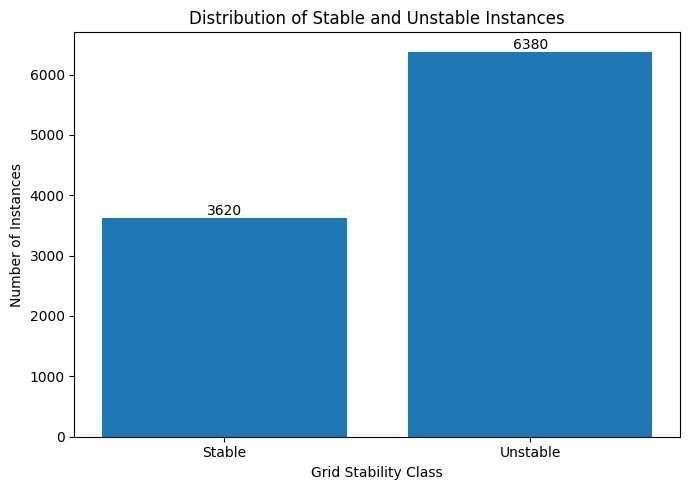

In [18]:

import matplotlib.pyplot as plt

# Class distribution from your dataset
classes = ["Stable", "Unstable"]
counts = [3620, 6380]

plt.figure(figsize=(7, 5))
bars = plt.bar(classes, counts)

plt.xlabel("Grid Stability Class")
plt.ylabel("Number of Instances")
plt.title("Distribution of Stable and Unstable Instances")

for bar, count in zip(bars, counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(count),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("fig2_class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


In [19]:

from google.colab import files
files.download("fig2_class_distribution.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>